# Step 11 — add all of KNHANES to the training data, test on NHANES

Does training on Korean data as well make the predictions for NHANES better?

**Design:** the same as step 9 k114: leave-one-cycle-out over the 7 NHANES cycles, inner leave-one-cycle-out for tuning, elastic net and XGBoost, the 114 features KNHANES has in both 2014 and 2016, outcome PHQ-9 ≥ 10.

**The one change:** all 10,518 KNHANES people from 2014 and 2016 (`nhanes/knhanes.py`) are added to every training set, both outer and inner. Testing and the validation folds used for tuning are NHANES only, so each test cycle can be compared with step 9 k114 directly. No country indicator is added; KNHANES rows enter the training set as they are.

Every KNHANES person is now used for training, so this model can no longer be tested on KNHANES (step 10 remains the external test of the NHANES-only model).

**Output:** `$NHANES_WORK/modeling/step11_knhanes_augment/`, with the same files as step 1.

`RUN = True` retrains (about 40 minutes on 4 threads) and needs the KNHANES files (`KNHANES_DATA`). `QUICK = True` with it runs one outer fold with the smallest grids. `RUN = False` only reads the saved results.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import plots  # noqa: E402
from nhanes.paths import RESULTS  # noqa: E402

RUN = False    # True: retrain and overwrite $NHANES_WORK/modeling/step11_knhanes_augment
QUICK = False  # with RUN: one outer fold, smallest grids
RUN = RUN or os.environ.get("NHANES_RUN") == "1"
QUICK = QUICK or os.environ.get("NHANES_QUICK") == "1"
OUT = RESULTS / "step11_knhanes_augment"
REF = RESULTS / "step9_knhanes_features" / "k114"
mapping = pd.read_csv(ROOT / "docs" / "knhanes_mapping.csv")
K114 = list(mapping.feature[mapping.years == "both"])

## Run

In [2]:
if RUN:
    from nhanes import knhanes
    from nhanes.loco import FEAT, NOT_FEATURES, run_loco
    data = pd.read_csv(FEAT / "features_2005_2018.csv.gz", usecols=NOT_FEATURES + K114)
    dic = pd.read_csv(FEAT / "feature_dictionary.csv").set_index("column").type.to_dict()
    kr = knhanes.load()
    extra = kr.assign(SEQN=np.nan, SDMVPSU=np.nan, SDMVSTRA=np.nan, WTINT2YR=np.nan,
                      WTMEC2YR=kr.wt_itvex)[NOT_FEATURES + K114]
    print(f"NHANES {len(data):,} rows; KNHANES added to every training set: {len(extra):,} rows")
    run_loco(data[NOT_FEATURES + K114], dic, OUT, QUICK, extra_train=extra,
             title="leave-one-cycle-out on NHANES, k114 features, all of KNHANES 2014 + 2016 added to training")

## Results

In [3]:
print((OUT / "report.txt").read_text())

leave-one-cycle-out on NHANES, k114 features, all of KNHANES 2014 + 2016 added to training

mean (sd) over test cycles, each cycle weighted equally:
         auroc        auroc_weighted         auprc         brier       
          mean    std           mean    std   mean    std   mean    std
model                                                                  
logreg   0.834  0.014          0.838  0.016  0.387  0.037  0.168  0.004
xgboost  0.833  0.011          0.836  0.015  0.391  0.031  0.160  0.004

AUROC of all out-of-cycle predictions pooled:
model
logreg     0.834
xgboost    0.833

per test cycle:
  model test_cycle  auroc  auroc_weighted  auprc  brier    n  prevalence  minutes
 logreg    2005-06  0.843           0.853  0.364  0.163 3975       0.062      9.7
xgboost    2005-06  0.843           0.850  0.394  0.155 3975       0.062      1.4
 logreg    2007-08  0.848           0.850  0.425  0.170 5104       0.098     10.1
xgboost    2007-08  0.843           0.846  0.423  0.162 510

Against step 9 k114 (the same design without KNHANES), test cycle by test cycle.

In [4]:
NAMES = {"logreg": "elastic net", "xgboost": "XGBoost"}
met = pd.concat([pd.read_csv(REF / "metrics.csv").assign(training="NHANES only (step 9 k114)"),
                 pd.read_csv(OUT / "metrics.csv").assign(training="NHANES + KNHANES (step 11)")])
cycles = sorted(set.intersection(*[set(g.test_cycle) for _, g in met.groupby("training")]))
met = met[met.test_cycle.isin(cycles)]
table = (met.groupby(["model", "training"], sort=False)[["auroc", "auprc", "brier"]].agg(["mean", "std"])
         .round(3))
display(table)
piv = met.pivot_table(index=["model", "test_cycle"], columns="training", values="auroc")
diff = (piv["NHANES + KNHANES (step 11)"] - piv["NHANES only (step 9 k114)"]).rename("AUROC change")
display(diff.unstack("model").rename(columns=NAMES).round(4))
for model, d in diff.groupby(level="model"):
    print(f"{NAMES[model]}: mean change {d.mean():+.4f} (min {d.min():+.4f}, max {d.max():+.4f}); "
          f"better in {(d > 0).sum()} of {len(d)} cycles")

auroc         auprc         brier       
                                     mean    std   mean    std   mean    std
model   training                                                            
logreg  NHANES only (step 9 k114)   0.834  0.013  0.389  0.036  0.160  0.005
xgboost NHANES only (step 9 k114)   0.833  0.011  0.392  0.030  0.153  0.005
logreg  NHANES + KNHANES (step 11)  0.834  0.014  0.387  0.037  0.168  0.004
xgboost NHANES + KNHANES (step 11)  0.833  0.011  0.391  0.031  0.160  0.004

model,elastic net,XGBoost
test_cycle,,
2005-06,-0.0008,0.0008
2007-08,-0.0000,-0.0010
2009-10,-0.0010,-0.0002
2011-12,0.0025,-0.0009
2013-14,0.0001,0.0002
2015-16,0.0027,-0.0011
2017-18,-0.0028,-0.0016


elastic net: mean change +0.0001 (min -0.0028, max +0.0027); better in 3 of 7 cycles
XGBoost: mean change -0.0005 (min -0.0016, max +0.0008); better in 2 of 7 cycles


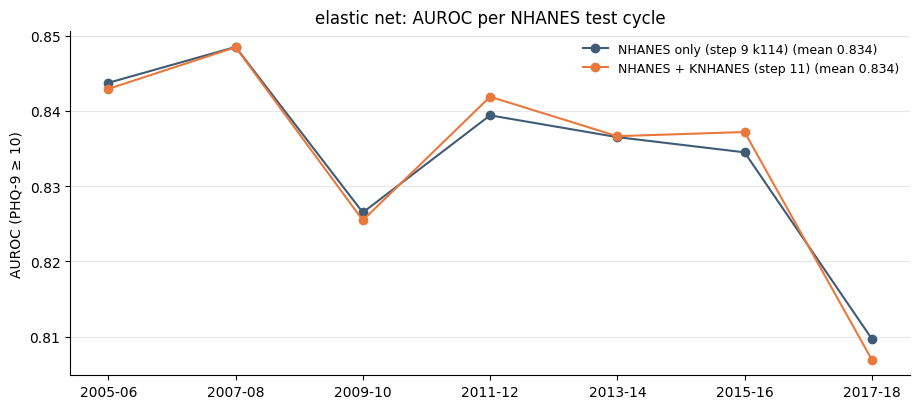

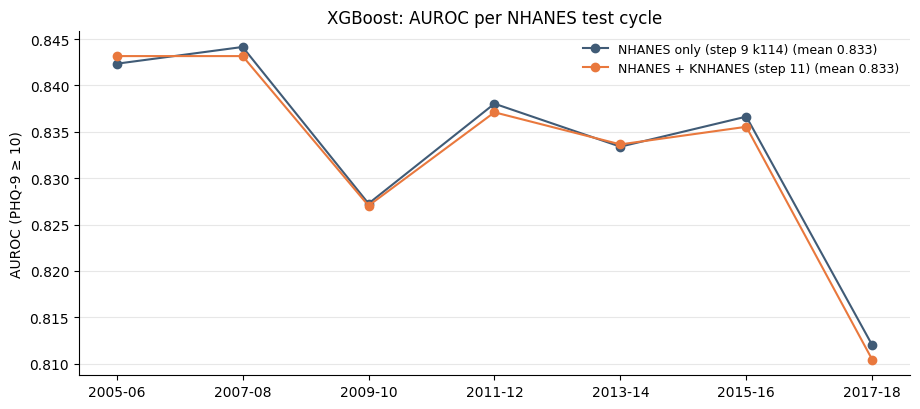

In [5]:
for model in NAMES:
    m = met[met.model == model].drop(columns="model").rename(columns={"training": "model"})
    plots.per_split_auroc(m, title=f"{NAMES[model]}: AUROC per NHANES test cycle")
    plots.show()